1 . Simple Gradient Descent Algorithm

In [46]:
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(0)
X = np.linspace(-5, 5, 50)
Y = (X > 0).astype(float)  


def f(w, b, x):
    # sigmoid
    return 1.0 / (1.0 + np.exp(-(w * x + b)))

def error(w, b, X, Y):
    err = 0.0
    for x, y in zip(X, Y):
        fx = f(w, b, x)
        err += 0.5 * (fx - y) ** 2
    return err

def grad_b(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx)

def grad_w(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx) * x


In [47]:
def do_gradient_descent(X, Y, eta=0.1, max_epochs=1000):
    w, b = -2.0, -2.0

    w_path, b_path = [], []

    for _ in range(max_epochs):
        dw, db = 0.0, 0.0

        for x, y in zip(X, Y):
            dw += grad_w(w, b, x, y)
            db += grad_b(w, b, x, y)

        w -= eta * dw
        b -= eta * db

        w_path.append(w)
        b_path.append(b)

    return w, b, w_path, b_path

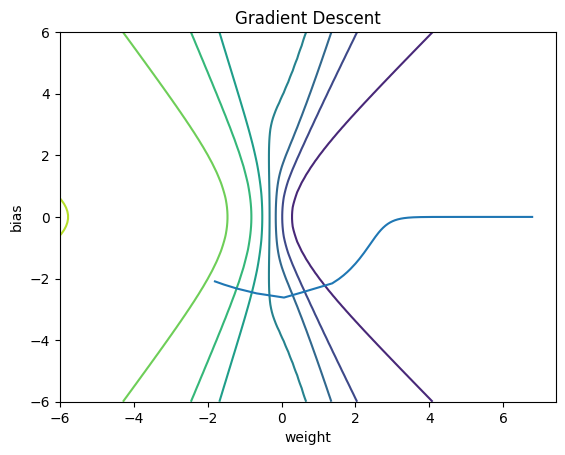

In [49]:
w_final, b_final, w_path, b_path = do_gradient_descent(X, Y)


w_vals = np.linspace(-6, 6, 100)
b_vals = np.linspace(-6, 6, 100)
W, B = np.meshgrid(w_vals, b_vals)

Z = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        Z[i, j] = error(W[i, j], B[i, j], X, Y)

plt.figure()
plt.contour(W, B, Z)
plt.plot(w_path, b_path)
plt.xlabel("weight")
plt.ylabel("bias")
plt.title("Gradient Descent")
plt.show()


2 . Momentum based Gradient Descent Algorithm (Batch, Stochastic, minibatch)

In [50]:

np.random.seed(0)
X = np.linspace(-5, 5, 50)
Y = (X > 0).astype(float)

def f(w, b, x):
    return 1.0 / (1.0 + np.exp(-(w * x + b)))


def error(w, b, X, Y):
    err = 0.0
    for x, y in zip(X, Y):
        fx = f(w, b, x)
        err += 0.5 * (fx - y) ** 2
    return err

def grad_b(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx)

def grad_w(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx) * x


In [51]:
def momentum_batch_gd(X, Y, eta=0.01, beta=0.9, epochs=1000):
    w, b = -2.0, -2.0
    vw, vb = 0.0, 0.0

    w_path, b_path = [], []

    for _ in range(epochs):
        dw, db = 0.0, 0.0

        for x, y in zip(X, Y):
            dw += grad_w(w, b, x, y)
            db += grad_b(w, b, x, y)

        vw = beta * vw + dw
        vb = beta * vb + db

        w -= eta * vw
        b -= eta * vb

        w_path.append(w)
        b_path.append(b)

    return w_path, b_path


In [52]:
def momentum_sgd(X, Y, eta=0.01, beta=0.9, epochs=50):
    w, b = -2.0, -2.0
    vw, vb = 0.0, 0.0

    w_path, b_path = [], []

    for _ in range(epochs):
        for x, y in zip(X, Y):
            dw = grad_w(w, b, x, y)
            db = grad_b(w, b, x, y)

            vw = beta * vw + dw
            vb = beta * vb + db

            w -= eta * vw
            b -= eta * vb

            w_path.append(w)
            b_path.append(b)

    return w_path, b_path


In [53]:
def momentum_minibatch_gd(X, Y, batch_size=10, eta=0.01, beta=0.9, epochs=200):
    w, b = -2.0, -2.0
    vw, vb = 0.0, 0.0

    w_path, b_path = [], []

    n = len(X)

    for _ in range(epochs):
        idx = np.random.permutation(n)
        X_shuff = X[idx]
        Y_shuff = Y[idx]

        for i in range(0, n, batch_size):
            dw, db = 0.0, 0.0
            xb = X_shuff[i:i+batch_size]
            yb = Y_shuff[i:i+batch_size]

            for x, y in zip(xb, yb):
                dw += grad_w(w, b, x, y)
                db += grad_b(w, b, x, y)

            vw = beta * vw + dw
            vb = beta * vb + db

            w -= eta * vw
            b -= eta * vb

            w_path.append(w)
            b_path.append(b)

    return w_path, b_path


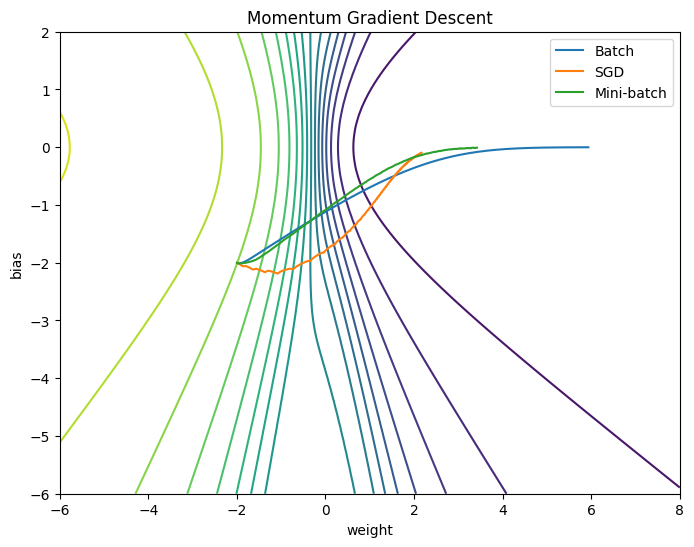

In [54]:
w_vals = np.linspace(-6, 8, 200)
b_vals = np.linspace(-6, 2, 200)
W, B = np.meshgrid(w_vals, b_vals)
Z = np.zeros_like(W)

for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        Z[i, j] = error(W[i, j], B[i, j], X, Y)
plt.figure(figsize=(8, 6))


plt.contour(W, B, Z, levels=20)


plt.plot(w_b, b_b, label="Batch")
plt.plot(w_s, b_s, label="SGD")
plt.plot(w_m, b_m, label="Mini-batch")

plt.xlabel("weight")
plt.ylabel("bias")
plt.legend()
plt.title("Momentum Gradient Descent")
plt.show()


3. Nesterov Accelerated Gradient Descent Algorithm (Batch, Stochastic, minibatch)

In [55]:

np.random.seed(0)
X = np.linspace(-5, 5, 50)
Y = (X > 0).astype(float)

def f(w, b, x):
    return 1.0 / (1.0 + np.exp(-(w * x + b)))

def error(w, b, X, Y):
    err = 0.0
    for x, y in zip(X, Y):
        fx = f(w, b, x)
        err += 0.5 * (fx - y) ** 2
    return err

def grad_b(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx)

def grad_w(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx) * x


In [56]:
def nesterov_batch_gd(X, Y, eta=0.01, beta=0.9, epochs=1000):
    w, b = -2.0, -2.0
    vw, vb = 0.0, 0.0

    w_path, b_path = [], []

    for _ in range(epochs):
        # look-ahead
        w_look = w - beta * vw
        b_look = b - beta * vb

        dw, db = 0.0, 0.0
        for x, y in zip(X, Y):
            dw += grad_w(w_look, b_look, x, y)
            db += grad_b(w_look, b_look, x, y)

        vw = beta * vw + dw
        vb = beta * vb + db

        w -= eta * vw
        b -= eta * vb

        w_path.append(w)
        b_path.append(b)

    return w_path, b_path


In [57]:
def nesterov_sgd(X, Y, eta=0.01, beta=0.9, epochs=50):
    w, b = -2.0, -2.0
    vw, vb = 0.0, 0.0

    w_path, b_path = [], []

    for _ in range(epochs):
        for x, y in zip(X, Y):
            w_look = w - beta * vw
            b_look = b - beta * vb

            dw = grad_w(w_look, b_look, x, y)
            db = grad_b(w_look, b_look, x, y)

            vw = beta * vw + dw
            vb = beta * vb + db

            w -= eta * vw
            b -= eta * vb

            w_path.append(w)
            b_path.append(b)

    return w_path, b_path


In [58]:
def nesterov_minibatch_gd(X, Y, batch_size=10, eta=0.01, beta=0.9, epochs=200):
    w, b = -2.0, -2.0
    vw, vb = 0.0, 0.0

    w_path, b_path = [], []
    n = len(X)

    for _ in range(epochs):
        idx = np.random.permutation(n)
        Xs, Ys = X[idx], Y[idx]

        for i in range(0, n, batch_size):
            w_look = w - beta * vw
            b_look = b - beta * vb

            dw, db = 0.0, 0.0
            xb = Xs[i:i+batch_size]
            yb = Ys[i:i+batch_size]

            for x, y in zip(xb, yb):
                dw += grad_w(w_look, b_look, x, y)
                db += grad_b(w_look, b_look, x, y)

            vw = beta * vw + dw
            vb = beta * vb + db

            w -= eta * vw
            b -= eta * vb

            w_path.append(w)
            b_path.append(b)

    return w_path, b_path


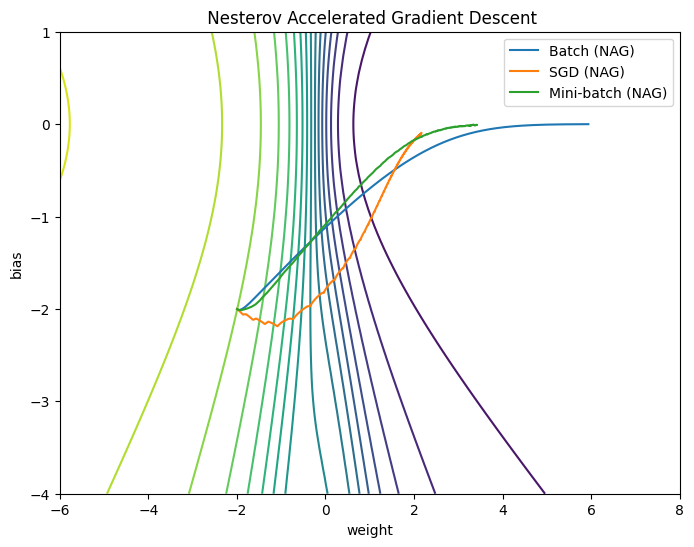

In [59]:
w_vals = np.linspace(-6, 8, 200)
b_vals = np.linspace(-4, 1, 200)
W, B = np.meshgrid(w_vals, b_vals)

Z = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        Z[i, j] = error(W[i, j], B[i, j], X, Y)

plt.figure(figsize=(8, 6))


plt.contour(W, B, Z, levels=20)

plt.plot(w_b, b_b, label="Batch (NAG)")
plt.plot(w_s, b_s, label="SGD (NAG)")
plt.plot(w_m, b_m, label="Mini-batch (NAG)")

plt.xlabel("weight")
plt.ylabel("bias")
plt.legend()
plt.title(" Nesterov Accelerated Gradient Descent")
plt.show()


4 . Gradient Descent Algorithm with Adagrad, RMSProp and ADAM optimizers.

In [60]:

np.random.seed(0)
X = np.linspace(-5, 5, 50)
Y = (X > 0).astype(float)

def f(w, b, x):
    return 1.0 / (1.0 + np.exp(-(w * x + b)))

def error(w, b, X, Y):
    e = 0.0
    for x, y in zip(X, Y):
        fx = f(w, b, x)
        e += 0.5 * (fx - y) ** 2
    return e

def grad_w(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx) * x

def grad_b(w, b, x, y):
    fx = f(w, b, x)
    return (fx - y) * fx * (1 - fx)


In [61]:
def adagrad_batch(X, Y, eta=0.5, eps=1e-8, epochs=500):
    w, b = -2.0, -2.0
    Gw, Gb = 0.0, 0.0
    w_path, b_path = [], []

    for _ in range(epochs):
        dw, db = 0.0, 0.0
        for x, y in zip(X, Y):
            dw += grad_w(w, b, x, y)
            db += grad_b(w, b, x, y)

        Gw += dw**2
        Gb += db**2

        w -= eta * dw / (np.sqrt(Gw) + eps)
        b -= eta * db / (np.sqrt(Gb) + eps)

        w_path.append(w)
        b_path.append(b)

    return w_path, b_path


In [62]:
def rmsprop_batch(X, Y, eta=0.01, beta=0.9, eps=1e-8, epochs=500):
    w, b = -2.0, -2.0
    Ew, Eb = 0.0, 0.0
    w_path, b_path = [], []

    for _ in range(epochs):
        dw, db = 0.0, 0.0
        for x, y in zip(X, Y):
            dw += grad_w(w, b, x, y)
            db += grad_b(w, b, x, y)

        Ew = beta * Ew + (1 - beta) * dw**2
        Eb = beta * Eb + (1 - beta) * db**2

        w -= eta * dw / (np.sqrt(Ew) + eps)
        b -= eta * db / (np.sqrt(Eb) + eps)

        w_path.append(w)
        b_path.append(b)

    return w_path, b_path


In [63]:
def adam_batch(X, Y, eta=0.01, beta1=0.9, beta2=0.999, eps=1e-8, epochs=500):
    w, b = -2.0, -2.0
    mw = mb = vw = vb = 0.0
    w_path, b_path = [], []

    for t in range(1, epochs + 1):
        dw, db = 0.0, 0.0
        for x, y in zip(X, Y):
            dw += grad_w(w, b, x, y)
            db += grad_b(w, b, x, y)

        mw = beta1 * mw + (1 - beta1) * dw
        mb = beta1 * mb + (1 - beta1) * db
        vw = beta2 * vw + (1 - beta2) * dw**2
        vb = beta2 * vb + (1 - beta2) * db**2

        mw_hat = mw / (1 - beta1**t)
        mb_hat = mb / (1 - beta1**t)
        vw_hat = vw / (1 - beta2**t)
        vb_hat = vb / (1 - beta2**t)

        w -= eta * mw_hat / (np.sqrt(vw_hat) + eps)
        b -= eta * mb_hat / (np.sqrt(vb_hat) + eps)

        w_path.append(w)
        b_path.append(b)

    return w_path, b_path


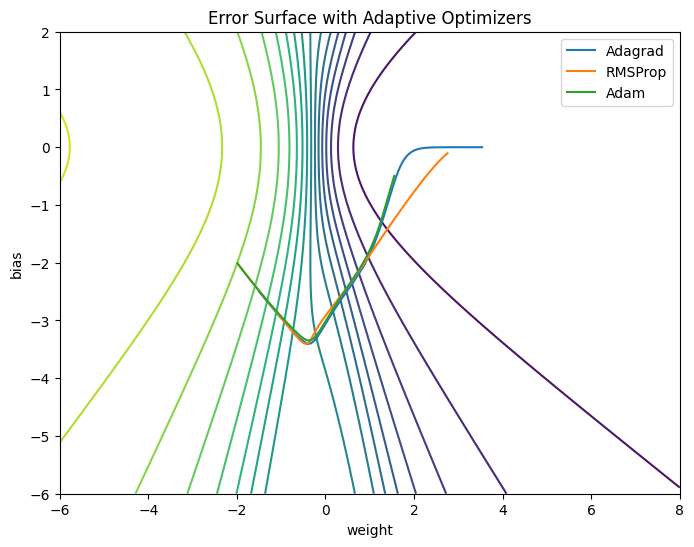

In [66]:
# Error surface
w_vals = np.linspace(-6, 8, 200)
b_vals = np.linspace(-6, 2, 200)
W, B = np.meshgrid(w_vals, b_vals)

Z = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        Z[i, j] = error(W[i, j], B[i, j], X, Y)


w_a, b_a = adagrad_batch(X, Y)
w_r, b_r = rmsprop_batch(X, Y)
w_ad, b_ad = adam_batch(X, Y)

plt.figure(figsize=(8,6))
plt.contour(W, B, Z, levels=20)
plt.plot(w_a, b_a, label="Adagrad")
plt.plot(w_r, b_r, label="RMSProp")
plt.plot(w_ad, b_ad, label="Adam")
plt.xlabel("weight")
plt.ylabel("bias")
plt.legend()
plt.title("Error Surface with Adaptive Optimizers")
plt.show()
